In [30]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

import arbitrage
import black_scholes
import ekf
import events
import kalman_filters
import plots
import utils
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [31]:
df_tickers = pl.read_csv("spy_options_tickers.csv")

In [32]:
df_tickers["ticker"][0]

'O:SPY240105C00270000'

In [33]:
option_ticker = df_tickers["ticker"][0]
client = MassiveClient()
df_quotes = client.fetch_quotes(option_ticker, date(2024, 1, 3))
df_trades = client.fetch_trades(option_ticker, date(2024, 1, 3))
df_spy = client.fetch_trades("SPY", date(2024, 1, 3))

In [34]:
strike, expiry, option_type = utils.parse_option_ticker(option_ticker)

df_trades_result, df_iv_trades_result, df_quotes_result, df_iv_quotes_result = (
    kalman_filters.kalman_filter_forward_window_last_all(
        df_trades=df_trades,
        df_quotes=df_quotes,
        df_spy=df_spy,
        strike=strike,
        expiry=expiry,
    )
)

In [35]:
# r2_price = utils.r_squared(df_trades_result["observed_price"], df_trades_result["trade_residual"])
# r2_iv = utils.r_squared(df_iv_trades_result["observed_iv"], df_iv_trades_result["trade_residual"])

# print(f"R² (price space): {r2_price:.4f}")
# print(f"R² (IV space):    {r2_iv:.4f}")

## IV Volatility Surface — all strikes

In [36]:
imp.reload(kalman_filters)
imp.reload(utils)

<module 'utils' from '/Users/elie/Documents/GitHub/quant_data/personal/personal_notebooks/utils.py'>

In [37]:
df_tickers

ticker,trade_count,ticker_suffix
str,i64,f64
"""O:SPY240105C00270000""",1,270000.0
"""O:SPY240105C00375000""",1,375000.0
"""O:SPY240105C00376000""",6,376000.0
"""O:SPY240105C00378000""",1,378000.0
"""O:SPY240105C00379000""",6,379000.0
…,…,…
"""O:SPY240105P00483000""",3,483000.0
"""O:SPY240105P00485000""",20,485000.0
"""O:SPY240105P00490000""",4,490000.0


In [38]:
# Build IV surface: runs the Kalman filter for every liquid option on the day.
# df_spy is reused from above (already fetched). min_trades filters out
# strikes with no real activity — raise it to keep only the most liquid ones.
trade_date = date(2024, 1, 3)

df_iv_surface_long = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    client=client,
    df_spy=df_spy,
    min_trades=100,
)
df_iv_surface_long

ts_ns,bid_iv,ask_iv,kalman_iv,strike
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.006736128 EST,0.138407,0.14335,0.140965,481.0
2024-01-03 09:30:00.006781440 EST,0.134058,0.139494,0.136943,479.0
2024-01-03 09:30:00.007484160 EST,0.132603,0.15164,0.141218,481.0
2024-01-03 09:30:00.008340992 EST,0.131082,0.144411,0.137207,479.0
2024-01-03 09:30:00.008425216 EST,0.132104,0.144187,0.138358,477.0
…,…,…,…,…
2024-01-03 16:14:55.718364928 EST,0.143009,0.143758,0.143391,470.0
2024-01-03 16:14:55.721362176 EST,0.1454,0.146126,0.14588,469.0
2024-01-03 16:14:57.942319616 EST,0.145401,0.146128,0.145766,469.0


In [39]:
# Synchronize: forward-fill each strike's IV onto the merged timestamp spine.
# Result is wide: one row per tick, columns bid_iv_402 / ask_iv_402 / kalman_iv_402 etc.
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_iv_surface_wide

ts_ns,bid_iv_454,ask_iv_454,kalman_iv_454,bid_iv_465,ask_iv_465,kalman_iv_465,bid_iv_466,ask_iv_466,kalman_iv_466,bid_iv_467,ask_iv_467,kalman_iv_467,bid_iv_468,ask_iv_468,kalman_iv_468,bid_iv_469,ask_iv_469,kalman_iv_469,bid_iv_470,ask_iv_470,kalman_iv_470,bid_iv_471,ask_iv_471,kalman_iv_471,bid_iv_472,ask_iv_472,kalman_iv_472,bid_iv_473,ask_iv_473,kalman_iv_473,bid_iv_474,ask_iv_474,kalman_iv_474,bid_iv_475,ask_iv_475,kalman_iv_475,bid_iv_476,ask_iv_476,kalman_iv_476,bid_iv_477,ask_iv_477,kalman_iv_477,bid_iv_478,ask_iv_478,kalman_iv_478,bid_iv_479,ask_iv_479,kalman_iv_479,bid_iv_480,ask_iv_480,kalman_iv_480,bid_iv_481,ask_iv_481,kalman_iv_481,bid_iv_482,ask_iv_482,kalman_iv_482,bid_iv_483,ask_iv_483,kalman_iv_483,bid_iv_484,ask_iv_484,kalman_iv_484,bid_iv_485,ask_iv_485,kalman_iv_485
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006736128 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.138407,0.14335,0.140965,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.006781440 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.134058,0.139494,0.136943,null,null,null,0.138407,0.14335,0.140965,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.007484160 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.134058,0.139494,0.136943,null,null,null,0.132603,0.15164,0.141218,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008340992 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.131082,0.144411,0.137207,null,null,null,0.132603,0.15164,0.141218,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008425216 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.132104,0.144187,0.138358,0.131152,0.143117,0.137422,0.131082,0.144411,0.137207,null,null,null,0.132603,0.15164,0.141218,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.718364928 EST,0.237895,0.337048,null,0.158442,0.167521,0.162554,0.155239,0.159367,0.157135,0.152156,0.153688,0.152906,0.148562,0.149296,0.148926,0.1454,0.146851,0.145859,0.143009,0.143758,0.143391,0.140562,0.142168,0.141121,0.140047,0.140953,0.140745,0.138843,0.140963,0.139345,0.137699,0.139006,0.138864,0.136707,0.138396,0.137668,0.136149,0.13842,0.137072,0.13307,0.136428,0.135321,0.132883,0.137763,0.135404,0.130984,0.138622,0.136602,0.141854,0.149969,0.1423,0.140201,0.152573,0.146438,0.150121,0.163174,0.15142,0.159958,0.173682,0.161289,0.169718,0.184098,0.170276,0.17884,0.193825,0.181204
2024-01-03 16:14:55.721362176 EST,0.237895,0.337048,null,0.158442,0.167521,0.162554,0.155239,0.159367,0.157135,0.152156,0.153688,0.152906,0.148562,0.149296,0.148926,0.1454,0.146126,0.14588,0.143009,0.143758,0

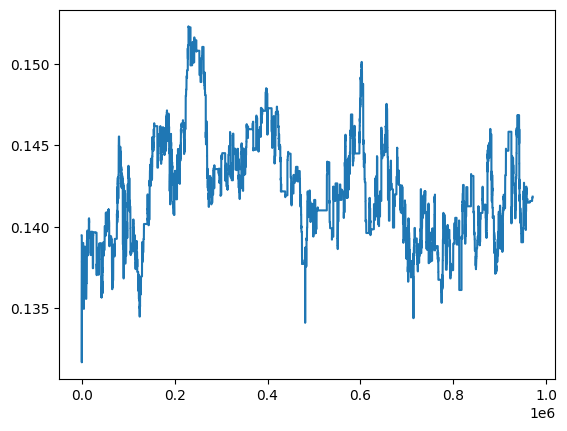

In [40]:
plt.plot(df_iv_surface_wide.select(pl.col("bid_iv_480")))

In [41]:
df_iv_surface_wide.shape

(970822, 67)

In [42]:
df_iv_surface_wide.select(pl.col("bid_iv_480").is_null()).sum()

bid_iv_480
u32
13


In [43]:
df_iv_surface_wide.select(pl.col("bid_iv_480").is_nan()).sum()

bid_iv_480
u32
0


In [44]:
import polars.selectors as cs

df_iv_surface_wide.select(
    pl.all().is_null().sum().name.suffix("_nulls"),
    cs.float().is_nan().sum().name.suffix("_nans"),
)

ts_ns_nulls,bid_iv_454_nulls,ask_iv_454_nulls,kalman_iv_454_nulls,bid_iv_465_nulls,ask_iv_465_nulls,kalman_iv_465_nulls,bid_iv_466_nulls,ask_iv_466_nulls,kalman_iv_466_nulls,bid_iv_467_nulls,ask_iv_467_nulls,kalman_iv_467_nulls,bid_iv_468_nulls,ask_iv_468_nulls,kalman_iv_468_nulls,bid_iv_469_nulls,ask_iv_469_nulls,kalman_iv_469_nulls,bid_iv_470_nulls,ask_iv_470_nulls,kalman_iv_470_nulls,bid_iv_471_nulls,ask_iv_471_nulls,kalman_iv_471_nulls,bid_iv_472_nulls,ask_iv_472_nulls,kalman_iv_472_nulls,bid_iv_473_nulls,ask_iv_473_nulls,kalman_iv_473_nulls,bid_iv_474_nulls,ask_iv_474_nulls,kalman_iv_474_nulls,bid_iv_475_nulls,ask_iv_475_nulls,kalman_iv_475_nulls,…,kalman_iv_473_nans,bid_iv_474_nans,ask_iv_474_nans,kalman_iv_474_nans,bid_iv_475_nans,ask_iv_475_nans,kalman_iv_475_nans,bid_iv_476_nans,ask_iv_476_nans,kalman_iv_476_nans,bid_iv_477_nans,ask_iv_477_nans,kalman_iv_477_nans,bid_iv_478_nans,ask_iv_478_nans,kalman_iv_478_nans,bid_iv_479_nans,ask_iv_479_nans,kalman_iv_479_nans,bid_iv_480_nans,ask_iv_480_nans,kalman_iv_480_nans,bid_iv_481_nans,ask_iv_481_nans,kalman_iv_481_nans,bid_iv_482_nans,ask_iv_482_nans,kalman_iv_482_nans,bid_iv_483_nans,ask_iv_483_nans,kalman_iv_483_nans,bid_iv_484_nans,ask_iv_484_nans,kalman_iv_484_nans,bid_iv_485_nans,ask_iv_485_nans,kalman_iv_485_nans
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,…,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,141942,91360,471175,1668,1547,748,734,852,34,426,246,53,5,5,5,35,35,35,23,23,23,29,29,29,10,10,10,26,26,26,18,18,18,17,17,17,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [45]:
df_iv_surface_wide.select(pl.col("kalman_iv_469").is_nan())

kalman_iv_469
bool
null
null
null
null
null
…
false
false
false


In [46]:
import polars.selectors as cs

df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

In [47]:
snapshot_ts = df_iv_surface_wide["ts_ns"].median()  # mid-day snapshot

In [48]:
snapshot_ts

datetime.datetime(2024, 1, 3, 13, 3, 19, 155793, tzinfo=zoneinfo.ZoneInfo(key='America/New_York'))

In [49]:
# Snapshot: pick a moment in time and plot the IV smile across strikes.
# join_asof gives the last known IV for each strike at that timestamp.
# snapshot_ts = df_iv_surface_wide["ts_ns"].median()  # mid-day snapshot

snapshot_ts = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)["ts_ns"][100]


row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
strikes_in_surface = sorted(df_iv_surface_long["strike"].unique().to_list())

mid_ivs = [row[f"kalman_iv_{int(k)}"][0] for k in strikes_in_surface]
bid_ivs = [row[f"bid_iv_{int(k)}"][0] for k in strikes_in_surface]
ask_ivs = [row[f"ask_iv_{int(k)}"][0] for k in strikes_in_surface]

import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=strikes_in_surface, y=mid_ivs, mode="lines+markers", name="kalman mid IV")
)
fig.add_trace(
    go.Scatter(x=strikes_in_surface, y=bid_ivs, mode="lines", name="bid IV", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=strikes_in_surface, y=ask_ivs, mode="lines", name="ask IV", line=dict(dash="dot"))
)
fig.update_layout(
    title=f"IV smile — {snapshot_ts}", xaxis_title="Strike", yaxis_title="Implied Vol"
)
fig.show()

In [50]:
tte = (expiry - snapshot_ts).total_seconds() / (365.25 * 24 * 3600)

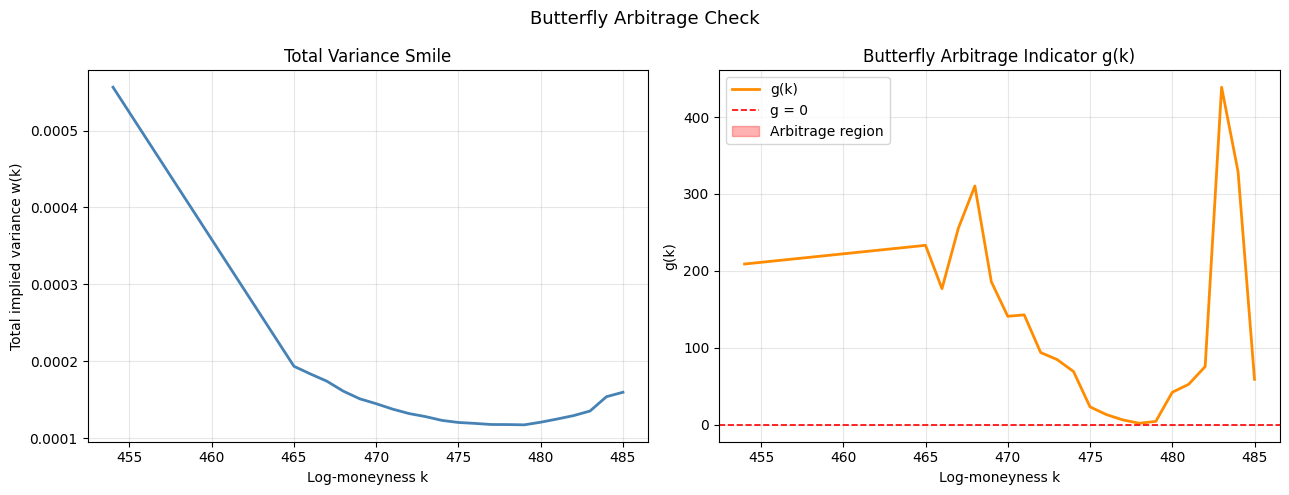

{'is_arbitrage_free': True,
 'min_g': 2.051013284492261,
 'violations': array([], dtype=float64),
 'g': array([208.99795809, 233.29922172, 176.95599563, 255.75922343,
        310.40052522, 186.04463726, 141.05231162, 142.94120078,
         93.96032636,  84.82583687,  69.23034856,  23.36933174,
         13.28641137,   6.37483922,   2.05101328,   4.49103963,
         42.27193886,  52.72686709,  75.72856046, 438.77782063,
        329.08064935,  59.14944919]),
 'w': array([0.00055633, 0.00019355, 0.00018359, 0.00017417, 0.00016122,
        0.00015127, 0.00014492, 0.00013785, 0.00013209, 0.00012812,
        0.00012319, 0.00012051, 0.0001193 , 0.00011786, 0.0001178 ,
        0.00011743, 0.00012085, 0.00012499, 0.00012944, 0.00013541,
        0.00015405, 0.00015978]),
 'k': array([454., 465., 466., 467., 468., 469., 470., 471., 472., 473., 474.,
        475., 476., 477., 478., 479., 480., 481., 482., 483., 484., 485.]),
 'lee_bound_ok': True}

In [51]:
arbitrage.check_butterfly(k=strikes_in_surface, iv=mid_ivs, T=tte, plot=True)

In [52]:
expiry

datetime.datetime(2024, 1, 5, 16, 0, tzinfo=<DstTzInfo 'America/New_York' LMT-1 day, 19:04:00 STD>)

In [53]:
(expiry - row["ts_ns"]).dt.total_seconds() / (365.25 * 24 * 3600)

ts_ns
f64
0.00621


In [54]:
df_filtered[0]["ts_ns"]

ts_ns
"datetime[ns, America/New_York]"
2024-01-03 09:30:00.232904704 EST


In [55]:
for i in range(0, df_filtered.shape[0], 100):
    row = df_filtered[i]
    strikes_in_surface = sorted(df_iv_surface_long["strike"].unique().to_list())
    mid_ivs = [row[f"kalman_iv_{int(k)}"][0] for k in strikes_in_surface]
    bid_ivs = [row[f"bid_iv_{int(k)}"][0] for k in strikes_in_surface]
    ask_ivs = [row[f"ask_iv_{int(k)}"][0] for k in strikes_in_surface]
    tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
    if not (
        arbitrage.check_butterfly(k=strikes_in_surface, iv=mid_ivs, T=tte, plot=False)[
            "is_arbitrage_free"
        ]
    ):
        print(f"Arbitrage detected at index {i} (timestamp {row['ts_ns'][0]})")

## IV Volatility Surface — puts

In [56]:
imp.reload(black_scholes)
imp.reload(events)
imp.reload(ekf)
imp.reload(kalman_filters)
imp.reload(utils)

<module 'utils' from '/Users/elie/Documents/GitHub/quant_data/personal/personal_notebooks/utils.py'>

In [57]:
df_iv_surface_long_puts = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    client=client,
    df_spy=df_spy,
    min_trades=100,
    option_type="P",
)
df_iv_surface_long_puts

ts_ns,bid_iv,ask_iv,kalman_iv,strike
"datetime[ns, America/New_York]",f64,f64,f64,f64
2024-01-03 09:30:00.008294144 EST,0.126374,0.129094,0.127734,471.0
2024-01-03 09:30:00.008504576 EST,0.140866,0.142808,0.141838,466.0
2024-01-03 09:30:00.008594688 EST,0.143561,0.145845,0.144708,465.0
2024-01-03 09:30:00.008790272 EST,0.144793,0.157957,0.151666,462.5
2024-01-03 09:30:00.008800256 EST,0.14515,0.159937,0.152947,462.0
…,…,…,…,…
2024-01-03 16:14:56.120656640 EST,0.074315,0.102375,0.094281,474.0
2024-01-03 16:14:59.884593152 EST,0.074304,0.104474,0.093967,474.0
2024-01-03 16:14:59.884598272 EST,0.108202,0.11439,0.110634,472.0


In [58]:
df_iv_surface_wide_puts = utils.synchronize_iv_surface(df_iv_surface_long_puts)
df_iv_surface_wide_puts

ts_ns,bid_iv_450,ask_iv_450,kalman_iv_450,bid_iv_458,ask_iv_458,kalman_iv_458,bid_iv_459,ask_iv_459,kalman_iv_459,bid_iv_460,ask_iv_460,kalman_iv_460,bid_iv_461,ask_iv_461,kalman_iv_461,bid_iv_462,ask_iv_462,kalman_iv_462,bid_iv_462_right,ask_iv_462_right,kalman_iv_462_right,bid_iv_463,ask_iv_463,kalman_iv_463,bid_iv_464,ask_iv_464,kalman_iv_464,bid_iv_465,ask_iv_465,kalman_iv_465,bid_iv_466,ask_iv_466,kalman_iv_466,bid_iv_467,ask_iv_467,kalman_iv_467,bid_iv_468,ask_iv_468,kalman_iv_468,bid_iv_469,ask_iv_469,kalman_iv_469,bid_iv_470,ask_iv_470,kalman_iv_470,bid_iv_471,ask_iv_471,kalman_iv_471,bid_iv_472,ask_iv_472,kalman_iv_472,bid_iv_473,ask_iv_473,kalman_iv_473,bid_iv_474,ask_iv_474,kalman_iv_474,bid_iv_475,ask_iv_475,kalman_iv_475,bid_iv_476,ask_iv_476,kalman_iv_476,bid_iv_477,ask_iv_477,kalman_iv_477
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.008294144 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.126374,0.129094,0.127734,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008504576 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.140866,0.142808,0.141838,null,null,null,null,null,null,null,null,null,null,null,null,0.126374,0.129094,0.127734,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008594688 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,null,null,null,null,null,null,null,null,null,null,null,null,0.126374,0.129094,0.127734,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008790272 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.144793,0.157957,0.151666,null,null,null,null,null,null,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,null,null,null,null,null,null,null,null,null,null,null,null,0.126374,0.129094,0.127734,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008800256 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.14515,0.159937,0.152947,0.144793,0.157957,0.151666,null,null,null,null,null,null,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,null,null,null,null,null,null,null,null,null,null,null,null,0.126374,0.129094,0.127734,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:56.120331008 EST,0.228638,0.240494,0.234176,0.159323,0.164147,0.161902,0.155297,0.159065,0.156091,0.148691,0.151775,0.150247,0.145427,0.147814,0.146758,0.140838,0.142743,0.142623,0.139924,0.141602,0.140745,0.137858,0.139364,0.139016,0.135908,0.137116,0.136183,0.133453,0.134466,0.13348,0.13062,0.131495,0.131054,0.128139,0.128922,0.12846,0.125068,0.12654,0.125707,0.122185,0.123636,0.122964,0.118936,0.121209,0.120059,0.115857,0.119229,0.116724,0.108204,0.114388,0.110967,0.094422,0.110671,0.104432,0.074315,0.102375,0.093847,0.136705,0.232821,null,0.060991,0.152455,null,0.085108,0.16783,null
2024-01-03 16:14:56.120656640 EST,0.228638,0.240494,0.234176,0.159323,0.164147,0.161902,0.155297,0.159065,0.156091,0.148691,0.151775,0.150247,0

In [61]:
df_filtered_puts = df_iv_surface_wide_puts.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_filtered_puts

ts_ns,bid_iv_450,ask_iv_450,kalman_iv_450,bid_iv_458,ask_iv_458,kalman_iv_458,bid_iv_459,ask_iv_459,kalman_iv_459,bid_iv_460,ask_iv_460,kalman_iv_460,bid_iv_461,ask_iv_461,kalman_iv_461,bid_iv_462,ask_iv_462,kalman_iv_462,bid_iv_462_right,ask_iv_462_right,kalman_iv_462_right,bid_iv_463,ask_iv_463,kalman_iv_463,bid_iv_464,ask_iv_464,kalman_iv_464,bid_iv_465,ask_iv_465,kalman_iv_465,bid_iv_466,ask_iv_466,kalman_iv_466,bid_iv_467,ask_iv_467,kalman_iv_467,bid_iv_468,ask_iv_468,kalman_iv_468,bid_iv_469,ask_iv_469,kalman_iv_469,bid_iv_470,ask_iv_470,kalman_iv_470,bid_iv_471,ask_iv_471,kalman_iv_471,bid_iv_472,ask_iv_472,kalman_iv_472,bid_iv_473,ask_iv_473,kalman_iv_473,bid_iv_474,ask_iv_474,kalman_iv_474,bid_iv_475,ask_iv_475,kalman_iv_475,bid_iv_476,ask_iv_476,kalman_iv_476,bid_iv_477,ask_iv_477,kalman_iv_477
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.214741248 EST,0.230729,0.251806,0.242532,0.173607,0.178062,0.17589,0.165913,0.173388,0.169421,0.160735,0.16694,0.163598,0.156514,0.159098,0.15788,0.152442,0.154546,0.154138,0.151297,0.153171,0.15244,0.149065,0.150761,0.150619,0.147238,0.14861,0.147927,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,0.135583,0.144061,0.138495,0.135564,0.138608,0.137088,0.133374,0.135494,0.134479,0.130254,0.132969,0.131612,0.126374,0.129094,0.127734,0.123567,0.126418,0.124954,0.118171,0.12294,0.120566,0.106322,0.111266,0.109975,0.109258,0.121062,0.114717,0.101497,0.122634,0.111283,0.011404,0.203654,0.103017
2024-01-03 09:30:00.215287552 EST,0.230729,0.251806,0.242532,0.173607,0.178062,0.17589,0.165913,0.173388,0.169421,0.160735,0.16694,0.163598,0.156514,0.159098,0.15788,0.152442,0.154546,0.154138,0.151297,0.153171,0.15244,0.149065,0.150761,0.150619,0.147238,0.14861,0.147927,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,0.135583,0.144061,0.138495,0.135564,0.138608,0.137088,0.133374,0.135494,0.134479,0.130254,0.132969,0.131612,0.126374,0.129094,0.127734,0.123567,0.126418,0.124954,0.118171,0.12294,0.120566,0.106322,0.111266,0.109975,0.109258,0.121062,0.114717,0.101497,0.122634,0.111283,0.088736,0.123154,0.104778
2024-01-03 09:30:00.216911360 EST,0.230729,0.251806,0.242532,0.173607,0.178062,0.17589,0.165913,0.173388,0.169421,0.160673,0.163865,0.163604,0.156514,0.159098,0.15788,0.152442,0.154546,0.154138,0.151297,0.153171,0.15244,0.149065,0.150761,0.150619,0.147238,0.14861,0.147927,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,0.139003,0.140696,0.139759,0.135564,0.138608,0.137088,0.133374,0.135494,0.134479,0.130254,0.132969,0.131612,0.126374,0.129094,0.127734,0.123567,0.126418,0.124954,0.118171,0.12294,0.120566,0.106322,0.111266,0.109975,0.109258,0.121062,0.114717,0.101497,0.122634,0.111283,0.088736,0.123154,0.104778
2024-01-03 09:30:00.217322240 EST,0.230729,0.251806,0.242532,0.173607,0.178062,0.17589,0.165913,0.173388,0.169421,0.160673,0.163865,0.163604,0.156514,0.159098,0.15788,0.152442,0.154546,0.154138,0.151297,0.153171,0.15244,0.149065,0.150761,0.150619,0.147238,0.14861,0.147927,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,0.139003,0.140696,0.139759,0.135564,0.138608,0.137088,0.133374,0.135494,0.134479,0.130934,0.13229,0.131613,0.126374,0.129094,0.127734,0.123567,0.126418,0.124954,0.118171,0.12294,0.120566,0.106322,0.111266,0.109975,0.109258,0.121062,0.114717,0.101497,0.122634,0.111283,0.088736,0.123154,0.104778
2024-01-03 09:30:00.217327360 EST,0.230729,0.251806,0.242532,0.173607,0.178062,0.17589,0.165856,0.169729,0.169412,0.160673,0.163865,0.163604,0.156514,0.159098,0.15788,0.152442,0.154546,0.154138,0.151297,0.153171,0.15244,0.149065,0.150761,0.150619,0.147238,0.14861,0.147927,0.143561,0.145845,0.144708,0.140866,0.142808,0.141838,0.139003,0.140696,0.139759,0.135564,0.138608,0.137088,0.133374,0.135494

In [62]:
snapshot_ts_puts = df_filtered_puts["ts_ns"][1000]
row_puts = df_iv_surface_wide_puts.filter(pl.col("ts_ns") <= snapshot_ts_puts).tail(1)
strikes_puts = sorted(df_iv_surface_long_puts["strike"].unique().to_list())
_, expiry_put, _ = utils.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("P"))["ticker"][0]
)

mid_ivs_puts = [row_puts[f"kalman_iv_{int(k)}"][0] for k in strikes_puts]
bid_ivs_puts = [row_puts[f"bid_iv_{int(k)}"][0] for k in strikes_puts]
ask_ivs_puts = [row_puts[f"ask_iv_{int(k)}"][0] for k in strikes_puts]

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=strikes_puts, y=mid_ivs_puts, mode="lines+markers", name="kalman mid IV")
)
fig.add_trace(
    go.Scatter(x=strikes_puts, y=bid_ivs_puts, mode="lines", name="bid IV", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=strikes_puts, y=ask_ivs_puts, mode="lines", name="ask IV", line=dict(dash="dot"))
)
fig.update_layout(
    title=f"Put IV smile — {snapshot_ts_puts}", xaxis_title="Strike", yaxis_title="Implied Vol"
)
fig.show()

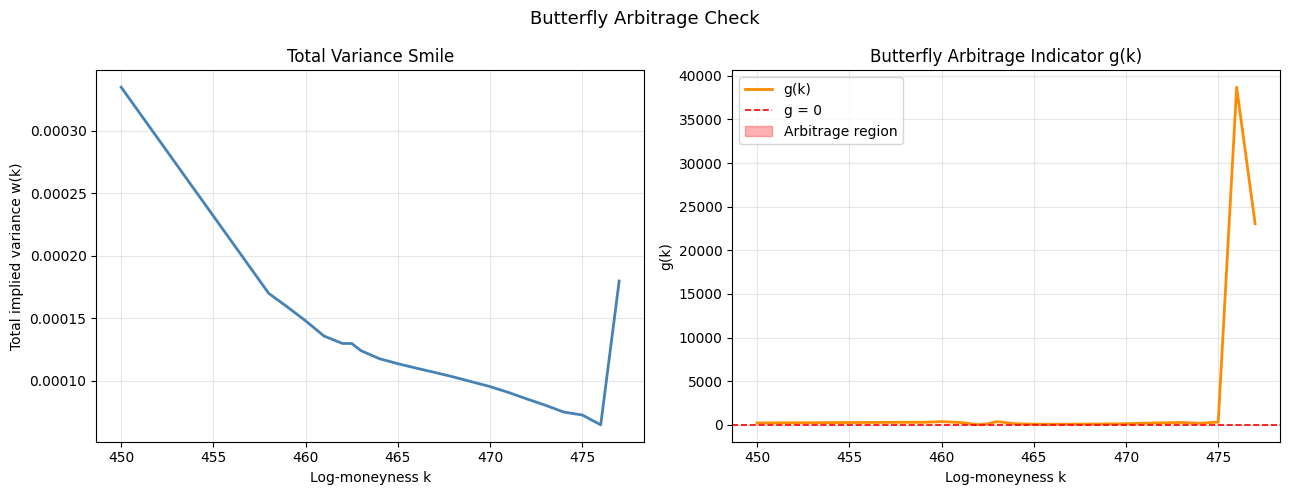

{'is_arbitrage_free': True,
 'min_g': 20.398327365868575,
 'violations': array([], dtype=float64),
 'g': array([2.20850019e+02, 2.90136661e+02, 2.84760649e+02, 3.68897196e+02,
        2.69016699e+02, 2.03983274e+01, 1.26372414e+02, 3.72870214e+02,
        1.27474352e+02, 7.66768522e+01, 7.09848871e+01, 7.49725504e+01,
        9.02709153e+01, 1.03740545e+02, 1.33688625e+02, 1.93277227e+02,
        2.29946645e+02, 2.72345943e+02, 1.78473403e+02, 3.14222250e+02,
        3.86840318e+04, 2.30476522e+04]),
 'w': array([3.34846864e-04, 1.69822144e-04, 1.59024326e-04, 1.47822251e-04,
        1.35621240e-04, 1.29698160e-04, 1.29698160e-04, 1.23954116e-04,
        1.17518873e-04, 1.13528922e-04, 1.09943899e-04, 1.06521529e-04,
        1.02956206e-04, 9.90408360e-05, 9.51973934e-05, 9.04832954e-05,
        8.52827157e-05, 8.02464846e-05, 7.47621762e-05, 7.24488882e-05,
        6.45575201e-05, 1.79691714e-04]),
 'k': array([450. , 458. , 459. , 460. , 461. , 462. , 462.5, 463. , 464. ,
        465

In [63]:
arbitrage.check_butterfly(k=strikes_puts, iv=mid_ivs_puts, T=tte, plot=True)

In [60]:
for i in range(0, df_filtered_puts.shape[0], 100):
    row = df_filtered_puts[i]
    strikes_in_surface = sorted(df_iv_surface_long_puts["strike"].unique().to_list())
    mid_ivs = [row[f"kalman_iv_{int(k)}"][0] for k in strikes_in_surface]
    bid_ivs = [row[f"bid_iv_{int(k)}"][0] for k in strikes_in_surface]
    ask_ivs = [row[f"ask_iv_{int(k)}"][0] for k in strikes_in_surface]
    tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
    if not (
        arbitrage.check_butterfly(k=strikes_in_surface, iv=mid_ivs, T=tte, plot=False)[
            "is_arbitrage_free"
        ]
    ):
        print(f"Arbitrage detected at index {i} (timestamp {row['ts_ns'][0]})")